# 02 — Prétraitement et encodage

**Rôle :** transformer les flux nettoyés en une matrice numérique adaptée à chaque famille de modèles,
**sans fuite d'information** : toutes les transformations sont *ajustées uniquement sur le train* puis
appliquées telles quelles au test et aux flux extraits d'un PCAP.

Le pipeline (`src/preprocessing.py`, `build_preprocessor`) est enchaîné au classifieur dans un
`Pipeline` scikit-learn : pendant la validation croisée, il est ré-ajusté dans chaque pli.

In [1]:
# Configuration : le notebook s'exécute depuis notebooks/, on ajoute la racine du dépôt au chemin
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from src import config as C
from src import visualization as V
pd.set_option('display.max_columns', 60); pd.set_option('display.width', 200)
print('Racine du projet :', ROOT.name)

Racine du projet : Network-Intrusion-Detection-System


## 1. Split stratifié train / test (80 / 20)
La stratification sur les 10 catégories garantit que les classes rares (Worms : 171 flux) sont présentes dans les deux jeux dans la même proportion.

In [2]:
train = pd.read_csv(C.TRAIN_FILE, low_memory=False); test = pd.read_csv(C.TEST_FILE, low_memory=False)
split = pd.DataFrame({'train': train.attack_cat.value_counts(), 'test': test.attack_cat.value_counts()}).reindex(C.ATTACK_CATEGORIES)
split['% train'] = (100 * split.train / split.train.sum()).round(2); split['% test'] = (100 * split.test / split.test.sum()).round(2)
display(split)
print(f"train : {len(train):,} | test : {len(test):,} | taux d'attaque train {train.label.mean():.3f} / test {test.label.mean():.3f}")

,train,test,% train,% test
attack_cat,,,,
Normal,45823,11456,62.74,62.75
Generic,4089,1022,5.60,5.60
Exploits,5112,1278,7.00,7.00
Fuzzers,5981,1495,8.19,8.19
DoS,2804,701,3.84,3.84
Reconnaissance,4791,1198,6.56,6.56
Analysis,1625,407,2.23,2.23
Backdoor,1504,376,2.06,2.06
Shellcode,1165,291,1.60,1.59


train : 73,031 | test : 18,258 | taux d'attaque train 0.373 / test 0.373


## 2. Les étapes du pipeline

| # | Étape | Rôle |
|---|---|---|
| 1 | `FeatureEngineer` | ajoute 5 features dérivées : `total_bytes`, `total_pkts`, `byte_ratio`, `pkt_ratio`, `bytes_per_pkt` (calculables aussi depuis un PCAP) |
| 2 | `SimpleImputer(median)` | ne jamais planter en inférence si une valeur manque |
| 3 | `SkewLog1p(seuil=2)` | `log1p` sur les colonnes dont l'asymétrie **du train** dépasse 2 (choix guidé par les tests de normalité) |
| 4 | `CorrelationFilter(0,95)` | retire une variable de chaque paire |r| > 0,95 (redondance) |
| 5 | `StandardScaler` (Z-score) | même échelle pour K-NN, SVM, régression logistique ; `MinMaxScaler` pour MultinomialNB (entrées positives) |
| 6 | `OneHotEncoder` | `proto`, `state`, `service` ; modalités < 30 occurrences regroupées (`infrequent`), modalités inconnues tolérées (indispensable pour un PCAP réel) |

In [3]:
from src.preprocessing import build_preprocessor, feature_frame
Xtr, Xte = feature_frame(train), feature_frame(test)
pre = build_preprocessor().fit(Xtr)            # ajusté sur le TRAIN uniquement
Ztr, Zte = pre.transform(Xtr), pre.transform(Xte)
names = list(pre.get_feature_names_out())
ct = pre.named_steps['columns']; num_pipe = ct.named_transformers_['num']; num_cols = ct.transformers_[0][2]
logged = [c for c, m in zip(num_cols, num_pipe.named_steps['log'].log_mask_) if m]
dropped = [c for c, m in zip(num_cols, num_pipe.named_steps['corr'].keep_mask_) if not m]
print(f"Entrée : {Xtr.shape[1]} colonnes → sortie : {Ztr.shape[1]} colonnes")
print(f"log1p appliqué à {len(logged)} variables : {logged}")
print(f"Supprimées par le filtre de corrélation : {dropped}")
onehot = ct.named_transformers_['cat'].named_steps['onehot']
for c, cats in zip(C.CATEGORICAL_FEATURES, onehot.categories_):
    print(f"  {c}: {len(cats)} modalités vues au train, {len([n for n in names if n.startswith(c + '_')])} colonnes One-Hot")

Entrée : 39 colonnes → sortie : 74 colonnes
log1p appliqué à 34 variables : ['dur', 'sbytes', 'dbytes', 'sloss', 'dloss', 'sload', 'dload', 'spkts', 'dpkts', 'smeansz', 'trans_depth', 'res_bdy_len', 'sjit', 'djit', 'sintpkt', 'dintpkt', 'tcprtt', 'synack', 'ackdat', 'is_sm_ips_ports', 'ct_flw_http_mthd', 'is_ftp_login', 'ct_ftp_cmd', 'ct_srv_src', 'ct_srv_dst', 'ct_dst_ltm', 'ct_src_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'total_bytes', 'total_pkts', 'byte_ratio', 'pkt_ratio']
Supprimées par le filtre de corrélation : ['dpkts', 'dwin', 'synack', 'ackdat', 'ct_ftp_cmd', 'total_pkts']
  proto: 133 modalités vues au train, 24 colonnes One-Hot
  state: 9 modalités vues au train, 5 colonnes One-Hot
  service: 13 modalités vues au train, 10 colonnes One-Hot


## 3. Effet des transformations sur une variable à queue lourde

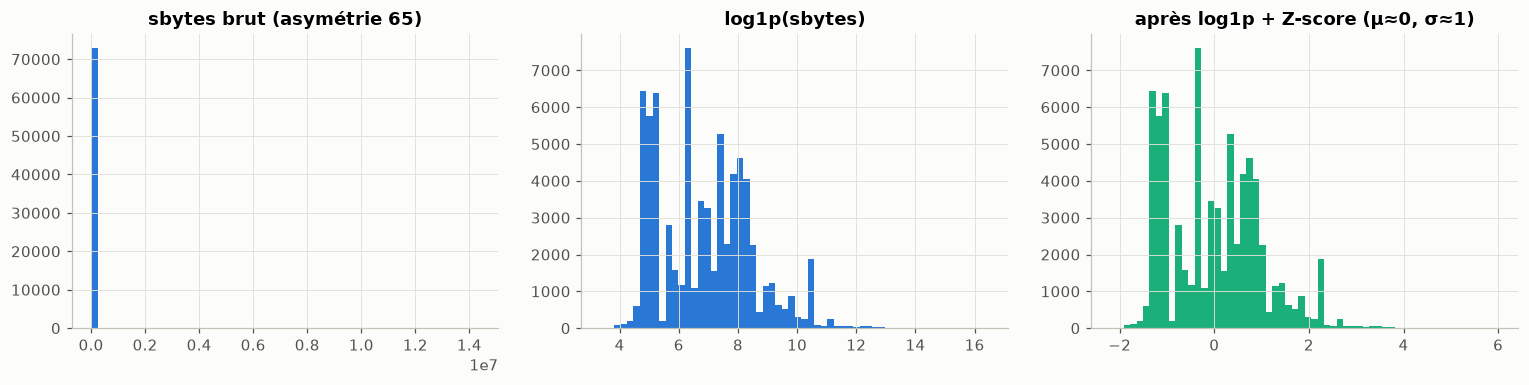

moyenne/écart-type après standardisation (train) : -0.0 1.0
moyenne/écart-type sur le test (non ré-ajusté)  : -0.0001 1.0012


In [4]:
i = names.index('sbytes')
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].hist(train.sbytes, bins=60, color=V.SERIES[0]); axes[0].set_title('sbytes brut (asymétrie %.0f)' % train.sbytes.skew())
axes[1].hist(np.log1p(train.sbytes), bins=60, color=V.SERIES[0]); axes[1].set_title('log1p(sbytes)')
axes[2].hist(Ztr[:, i], bins=60, color=V.SERIES[2]); axes[2].set_title('après log1p + Z-score (μ≈0, σ≈1)')
plt.tight_layout(); V.save(fig, '02_transformations_sbytes'); plt.show()
print('moyenne/écart-type après standardisation (train) :', Ztr[:, i].mean().round(4), Ztr[:, i].std().round(4))
print('moyenne/écart-type sur le test (non ré-ajusté)  :', Zte[:, i].mean().round(4), Zte[:, i].std().round(4))

Le test a une moyenne proche mais pas exactement nulle : c'est **normal et souhaité** — les paramètres
(moyenne, écart-type, seuils, catégories) viennent du train seul ; les recalculer sur le test serait une fuite.

## 4. Profil « portable » (sans TTL)
Même pipeline en retirant `sttl`, `dttl`, `ct_state_ttl` (artefact du banc de test).

In [5]:
pre_p = build_preprocessor(drop=C.TTL_FEATURES).fit(Xtr)
print('Colonnes profil portable :', len(pre_p.get_feature_names_out()), '| profil complet :', len(names))

Colonnes profil portable : 71 | profil complet : 74


## 5. Compatibilité avec les flux extraits d'un PCAP
Le même pipeline accepte les tuples produits par l'extracteur (notebook 07) — y compris des protocoles ou services jamais vus.

In [6]:
from src.pcap import pcap_to_flows
from src.preprocessing import clean_dataframe
pcap = C.SAMPLE_PCAP_DIR / 'demo_unsw_testbed.pcap'
if not pcap.exists():
    from src.pcap.generator import generate_demo_pcap; generate_demo_pcap(pcap)
flows = pcap_to_flows(pcap)
Zp = pre.transform(feature_frame(clean_dataframe(flows)))
print(f"{len(flows)} flux extraits → matrice {Zp.shape}, valeurs finies : {np.isfinite(Zp).all()}")

428 flux extraits → matrice (428, 74), valeurs finies : True
